In [10]:

from pathlib import Path
import subprocess
import shutil
import os
import sys
import numpy as np

# 1. Dataset-i qe kemi lidhur ne Kaggle
dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup"
)

# 2. Folderi i projektit ESA
repo = Path("/kaggle/working/SpOC2")
project = repo / "Morphing Rovers"

# 3. Shkarkojme projektin ESA nese mungon
if not repo.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/esa/SpOC2.git",
        str(repo)
    ], check=True)

print("Projekti ESA eshte gati!")

# 4. Kopjojme fajllat nga Dataset-i
for file in dataset.iterdir():
    if file.is_file():
        shutil.copy2(file, project / file.name)

print("Fajllat u rikthyen!")

# 5. Hyjme ne folderin e projektit
os.chdir(project)
sys.path.insert(0, str(project))

# 6. Hapim simulatorin
import morphing_kaggle as m

udp = m.morphing_rover_UDP()

print("Simulatori u hap me sukses!")

# 7. Kontrollojme konfigurimet
for seed in [101, 202, 303]:
    rs = (project / f"rs_seed_{seed}.npy").exists()
    ga = (project / f"ga_seed_{seed}.npy").exists()

    print(f"Seed {seed}: RS={rs}, GA={ga}")



Projekti ESA eshte gati!
Fajllat u rikthyen!
Simulatori u hap me sukses!
Seed 101: RS=True, GA=True
Seed 202: RS=True, GA=True
Seed 303: RS=True, GA=True


In [11]:

import numpy as np
from pathlib import Path

# Kontrollojme robotin fillestar
original = np.array(udp.example(), dtype=float)

print("Numri i parametrave:", len(original))

# Kontrollojme konfigurimet e ruajtura
for seed in [101, 202, 303]:
    rs = np.load(project / f"rs_seed_{seed}.npy")
    ga = np.load(project / f"ga_seed_{seed}.npy")

    print(
        f"Seed {seed}: "
        f"RS = {len(rs)} parametra, "
        f"GA = {len(ga)} parametra"
    )

print("\nKonfigurimet jane gati per testim!")


Numri i parametrave: 19133
Seed 101: RS = 19133 parametra, GA = 19133 parametra
Seed 202: RS = 19133 parametra, GA = 19133 parametra
Seed 303: RS = 19133 parametra, GA = 19133 parametra

Konfigurimet jane gati per testim!


In [12]:

from pathlib import Path
import shutil
import pandas as pd

# Dataset-i me rezultatet e fundit
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Kopjojme fajllat e versionit V2
for file in dataset_v2.iterdir():
    if file.is_file():
        shutil.copy2(file, project / file.name)

print("Fajllat V2 u kopjuan me sukses!")

# Lexojme rezultatet perfundimtare
results = pd.read_csv(
    project / "seed_full_30_summary.csv"
)

print("\nREZULTATET PERFUNDIMTARE")
print(results.to_string(index=False))


Fajllat V2 u kopjuan me sukses!

REZULTATET PERFUNDIMTARE
        Algoritmi  Fitness_Mesatar  Devijimi_Standard  Permiresimi_Mesatar  Koha_Testimit_Mesatare
Genetic Algorithm         6.184105           0.514357            22.497136               32.100833
    Random Search         6.652622           1.151111            16.625401               31.590219


In [13]:

import numpy as np

# Konfigurimi fillestar i robotit
base = np.array(udp.example(), dtype=float)

# Kufijte e parametrave
lower, upper = udp.get_bounds()
lower = np.array(lower)
upper = np.array(upper)

# Numri i parametrave te vazhdueshem
n_cont = len(base) - udp.get_nix()

# Skenaret e trajnimit
cases = [(0, 0), (0, 1), (1, 0)]

# Funksioni i vleresimit
def evaluate(params):
    robot = m.Rover(params)
    scores = []

    for map_id, scenario_id in cases:
        d, t = udp.run_single_scenario(
            robot, map_id, scenario_id
        )
        scores.append((1 + float(d)) * float(t))

    return float(np.mean(scores))


# Funksioni i mutacionit
def mutate(parent, rng):
    child = parent.copy()

    ids = rng.choice(
        n_cont, size=700, replace=False
    )

    child[ids] += rng.normal(
        0, 0.5, size=len(ids)
    )

    child[:n_cont] = np.clip(
        child[:n_cont],
        lower[:n_cont],
        upper[:n_cont]
    )

    return child


# ALGORITMI 1 - RANDOM SEARCH
def random_search(seed=2026):
    rng = np.random.default_rng(seed)

    best = base.copy()
    best_score = evaluate(best)

    for i in range(11):
        candidate = mutate(base, rng)
        score = evaluate(candidate)

        if score < best_score:
            best = candidate.copy()
            best_score = score

    return best, best_score


# ALGORITMI 2 - GENETIC ALGORITHM
def genetic_algorithm(seed=2026):
    rng = np.random.default_rng(seed + 5000)

    # Popullata fillestare
    population = [(base.copy(), evaluate(base))]

    for i in range(3):
        child = mutate(base, rng)
        population.append((child, evaluate(child)))

    # Kater gjenerata te tjera
    for generation in range(4):
        population.sort(key=lambda item: item[1])

        parent1 = population[0][0]
        parent2 = population[1][0]

        children = []

        for i in range(2):
            # Crossover
            mask = rng.random(n_cont) < 0.5
            child = parent1.copy()

            child[:n_cont] = np.where(
                mask,
                parent1[:n_cont],
                parent2[:n_cont]
            )

            # Mutation
            child = mutate(child, rng)
            score = evaluate(child)

            children.append((child, score))

        # Elitism
        population = population[:2] + children

    population.sort(key=lambda item: item[1])

    return population[0]


print("Random Search dhe Genetic Algorithm jane gati!")


Random Search dhe Genetic Algorithm jane gati!


In [14]:

import pandas as pd
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet e ruajtura
df = pd.read_csv(
    project / "final_comparison.csv"
)

# Rendisim nga rezultati me i mire
df = df.sort_values("Fitness")

print("KRAHASIMI I ALGORITMEVE")
print(df.round(4).to_string(index=False))

print("\nRezultatet u lexuan me sukses!")


KRAHASIMI I ALGORITMEVE
                    Algoritmi  Fitness  Permiresimi_%
    Random Search Independent   6.0191        24.5647
             Random Search V1   6.4268        19.4559
             Roboti fillestar   7.9792         0.0000
Genetic Algorithm Independent   7.9792         0.0000

Rezultatet u lexuan me sukses!


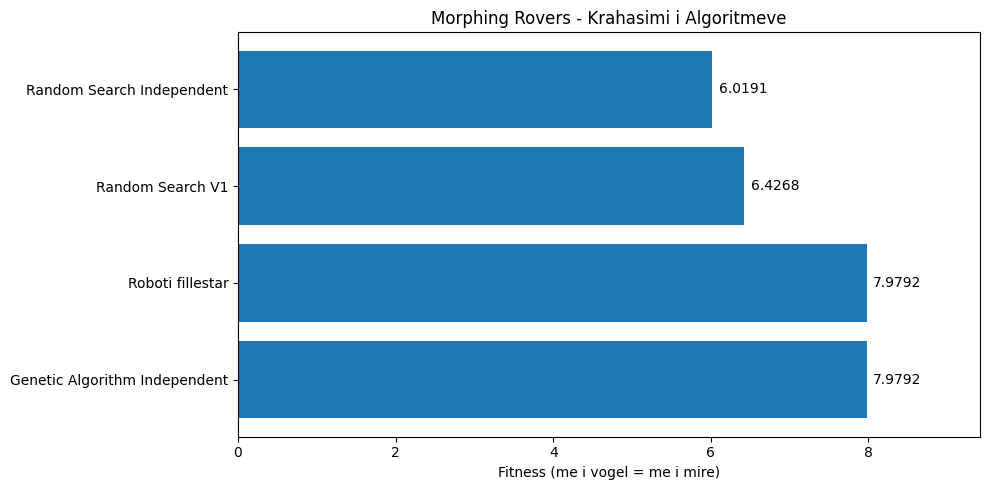

Grafiku u krijua dhe u ruajt me sukses!


In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folderi i projektit
project = Path("/kaggle/working/SpOC2/Morphing Rovers")

# Lexojme rezultatet e ruajtura
df_plot = pd.read_csv(project / "final_comparison.csv")

# Rendisim sipas fitness
df_plot = df_plot.sort_values("Fitness")

# Krijojme grafikun
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    df_plot["Algoritmi"],
    df_plot["Fitness"]
)

ax.invert_yaxis()

ax.set_title("Morphing Rovers - Krahasimi i Algoritmeve")
ax.set_xlabel("Fitness (me i vogel = me i mire)")

# Shfaqim vlerat
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

ax.set_xlim(0, df_plot["Fitness"].max() * 1.18)

plt.tight_layout()

# Ruajme grafikun
plt.savefig(
    project / "fitness_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafiku u krijua dhe u ruajt me sukses!")


In [16]:

import pandas as pd
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet e eksperimenteve
seed_results = pd.read_csv(
    project / "seed_experiments.csv"
)

print("REZULTATET E EKSPERIMENTEVE")
print(seed_results.round(4).to_string(index=False))

# Llogarisim statistikat
summary = seed_results.groupby("Algoritmi").agg(
    Fitness_Mesatar=("Fitness", "mean"),
    Devijimi_Standard=("Fitness", "std"),
    Koha_Mesatare_s=("Koha_s", "mean")
)

print("\nPERMBLEDHJA")
print(summary.round(4))

print("\nRezultatet u lexuan me sukses!")


REZULTATET E EKSPERIMENTEVE
 Seed         Algoritmi  Fitness  Koha_s
  101     Random Search   3.1823 34.8514
  101 Genetic Algorithm   4.0568 25.9736
  202     Random Search   3.0216 27.5774
  202 Genetic Algorithm   3.4670 25.0398
  303     Random Search   4.4900 17.4280
  303 Genetic Algorithm   4.1173 29.8869

PERMBLEDHJA
                   Fitness_Mesatar  Devijimi_Standard  Koha_Mesatare_s
Algoritmi                                                             
Genetic Algorithm           3.8804             0.3593          26.9668
Random Search               3.5647             0.8054          26.6189

Rezultatet u lexuan me sukses!


In [17]:

import pandas as pd
from pathlib import Path
import shutil

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Dataset V2 me rezultatet e ruajtura
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Rikthejme rezultatet nga Dataset V2
for name in [
    "seed_full_30_results.csv",
    "seed_full_30_summary.csv"
]:
    source = dataset_v2 / name
    destination = project / name

    shutil.copy2(source, destination)
    print("U rikthye:", name)

# Lexojme rezultatet e 30 skenareve
df_full = pd.read_csv(
    project / "seed_full_30_results.csv"
)

print("\nREZULTATET NE 30 SKENARE")
print(df_full.round(4).to_string(index=False))

# Llogarisim statistikat perfundimtare
summary_full = df_full.groupby("Algoritmi").agg(
    Fitness_Mesatar=("Fitness_30", "mean"),
    Devijimi_Standard=("Fitness_30", "std"),
    Permiresimi_Mesatar=("Permiresimi_%", "mean"),
    Koha_Testimit_Mesatare=("Koha_testimit_s", "mean")
)

print("\nPERMBLEDHJA PERFUNDIMTARE")
print(summary_full.round(4))

print("\nRezultatet u lexuan me sukses!")


U rikthye: seed_full_30_results.csv
U rikthye: seed_full_30_summary.csv

REZULTATET NE 30 SKENARE
 Seed         Algoritmi  Fitness_30  Permiresimi_%  Koha_testimit_s
  101     Random Search      6.0615        24.0336          35.2311
  101 Genetic Algorithm      6.0940        23.6263          33.4959
  202     Random Search      5.9172        25.8426          31.5651
  202 Genetic Algorithm      5.7208        28.3042          32.7845
  303     Random Search      7.9792         0.0000          27.9745
  303 Genetic Algorithm      6.7376        15.5609          30.0222

PERMBLEDHJA PERFUNDIMTARE
                   Fitness_Mesatar  Devijimi_Standard  Permiresimi_Mesatar  \
Algoritmi                                                                    
Genetic Algorithm           6.1841             0.5144              22.4971   
Random Search               6.6526             1.1511              16.6254   

                   Koha_Testimit_Mesatare  
Algoritmi                                 

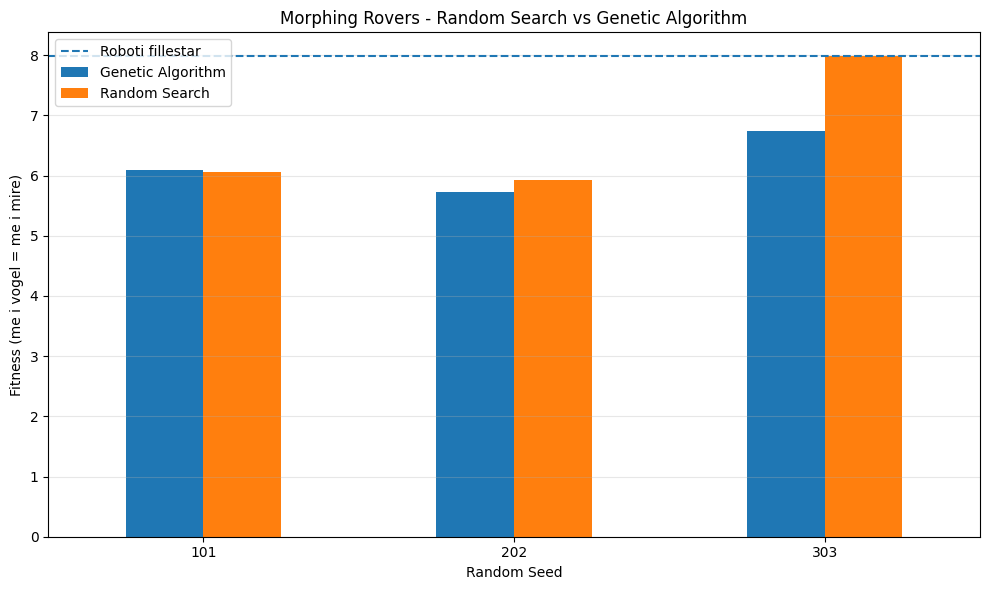

Grafiku perfundimtar u krijua me sukses!


In [18]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet nga Dataset V2
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

df = pd.read_csv(
    dataset_v2 / "seed_full_30_results.csv"
)

# Organizojme rezultatet sipas seed
pivot = df.pivot(
    index="Seed",
    columns="Algoritmi",
    values="Fitness_30"
)

# Krijojme grafikun
fig, ax = plt.subplots(figsize=(10, 6))

pivot.plot(
    kind="bar",
    ax=ax,
    rot=0
)

# Rezultati i robotit fillestar
baseline = 7.9792

ax.axhline(
    y=baseline,
    linestyle="--",
    label="Roboti fillestar"
)

ax.set_title(
    "Morphing Rovers - Random Search vs Genetic Algorithm"
)

ax.set_xlabel("Random Seed")
ax.set_ylabel("Fitness (me i vogel = me i mire)")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Ruajme grafikun
plt.savefig(
    project / "comparison_30_scenarios.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafiku perfundimtar u krijua me sukses!")
